In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
file_path = "/content/drive/MyDrive/Data/piggery_data.csv"

In [5]:
rows = []

with open(file_path, "r") as f:
    current_channel = None
    current_unit = None
    interval_minutes = None

    for line in f:
        parts = line.strip().split(",")

        if len(parts) < 2:
            continue

        # Header row
        if parts[0] == "200":
            current_channel = parts[3]
            current_unit = parts[7]
            interval_minutes = int(parts[8])

        # Data row
        elif parts[0] == "300":

            # only use B1 + KWH
            if current_channel == "B1" and current_unit == "KWH":

                date = parts[1]
                values = parts[2:]

                for i, value in enumerate(values):

                    try:
                        kwh = float(value)
                    except:
                        continue

                    # remove zero values
                    if kwh <= 0:
                        continue

                    timestamp = (
                        pd.to_datetime(date, format="%Y%m%d")
                        + pd.Timedelta(minutes=i * interval_minutes)
                    )

                    rows.append({
                        "datetime": timestamp,
                        "demand_kWh_5min": kwh,
                        "demand_kW": kwh * 12
                    })

df = pd.DataFrame(rows)

print(df.head())
print(df.shape)

             datetime  demand_kWh_5min     demand_kW
0 2024-05-05 00:15:00     2.024051e+13  2.428861e+14
1 2024-05-06 00:15:00     2.024051e+13  2.428861e+14
2 2024-05-07 00:15:00     2.024051e+13  2.428861e+14
3 2024-05-08 00:15:00     2.024051e+13  2.428861e+14
4 2024-05-09 00:15:00     2.024051e+13  2.428861e+14
(729, 3)


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import re

rows = []

with open(file_path, "r") as f:
    current_unit = None
    current_channel = None
    interval_minutes = 5

    for line in f:
        parts = [p.strip() for p in line.strip().split(",") if p.strip() != ""]

        if len(parts) < 2:
            continue

        # Header row
        if parts[0] == "200":
            current_unit = "KWH" if "KWH" in parts else None

            # try to find channel before KWH
            if "KWH" in parts:
                kwh_index = parts.index("KWH")
                current_channel = parts[kwh_index - 1] if kwh_index >= 1 else None

                # interval usually appears after KWH
                for p in parts[kwh_index + 1:]:
                    if p.isdigit():
                        interval_minutes = int(p)
                        break

        # Data row
        elif parts[0] == "300" and current_unit == "KWH":

            # find date position, e.g. 20240504
            date_index = None
            for i, p in enumerate(parts):
                if re.fullmatch(r"20\d{6}", p):
                    date_index = i
                    break

            if date_index is None:
                continue

            date = parts[date_index]
            values = parts[date_index + 1:]

            for i, value in enumerate(values):
                try:
                    kwh = float(value)
                except:
                    continue

                # remove zero and impossible values
                if kwh <= 0 or kwh > 100:
                    continue

                timestamp = (
                    pd.to_datetime(date, format="%Y%m%d")
                    + pd.Timedelta(minutes=i * interval_minutes)
                )

                rows.append({
                    "datetime": timestamp,
                    "channel": current_channel,
                    "demand_kWh_5min": kwh,
                    "demand_kW": kwh * (60 / interval_minutes)
                })

df = pd.DataFrame(rows)

print(df.head())
print(df.shape)
print(df["channel"].unique())
print(df["demand_kWh_5min"].describe())

             datetime    channel  demand_kWh_5min  demand_kW
0 2024-05-04 00:00:00  219681948             2.81      33.72
1 2024-05-04 00:05:00  219681948             2.97      35.64
2 2024-05-04 00:10:00  219681948             2.90      34.80
3 2024-05-04 00:15:00  219681948             2.89      34.68
4 2024-05-04 00:20:00  219681948             2.99      35.88
(209506, 4)
['219681948']
count    209506.000000
mean          4.680776
std           1.628315
min           0.160000
25%           3.450000
50%           4.120000
75%           5.550000
max          11.210000
Name: demand_kWh_5min, dtype: float64


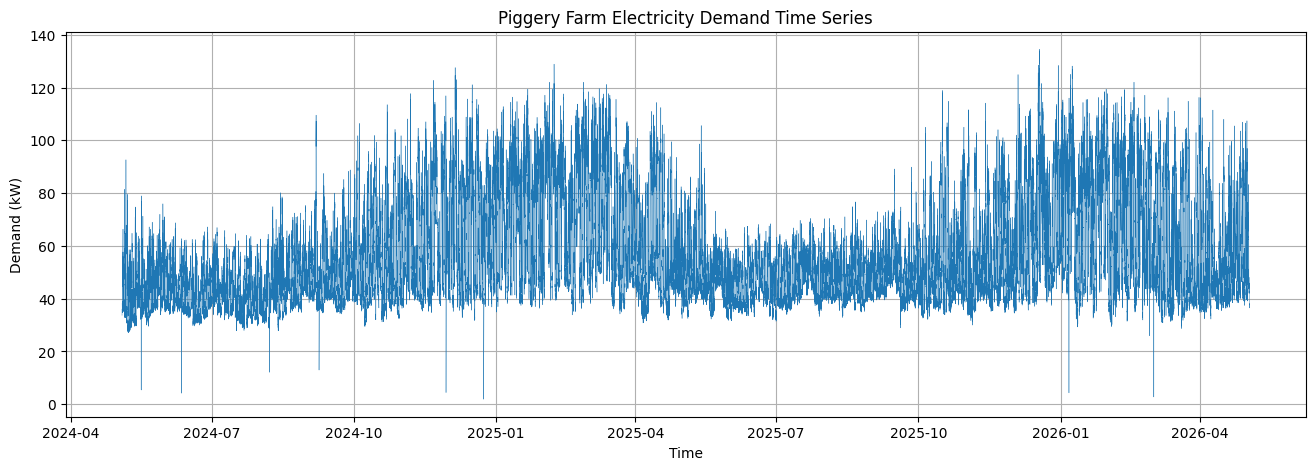

In [8]:
plt.figure(figsize=(16, 5))
plt.plot(df["datetime"], df["demand_kW"], linewidth=0.3)

plt.xlabel("Time")
plt.ylabel("Demand (kW)")
plt.title("Piggery Farm Electricity Demand Time Series")
plt.grid(True)
plt.show()

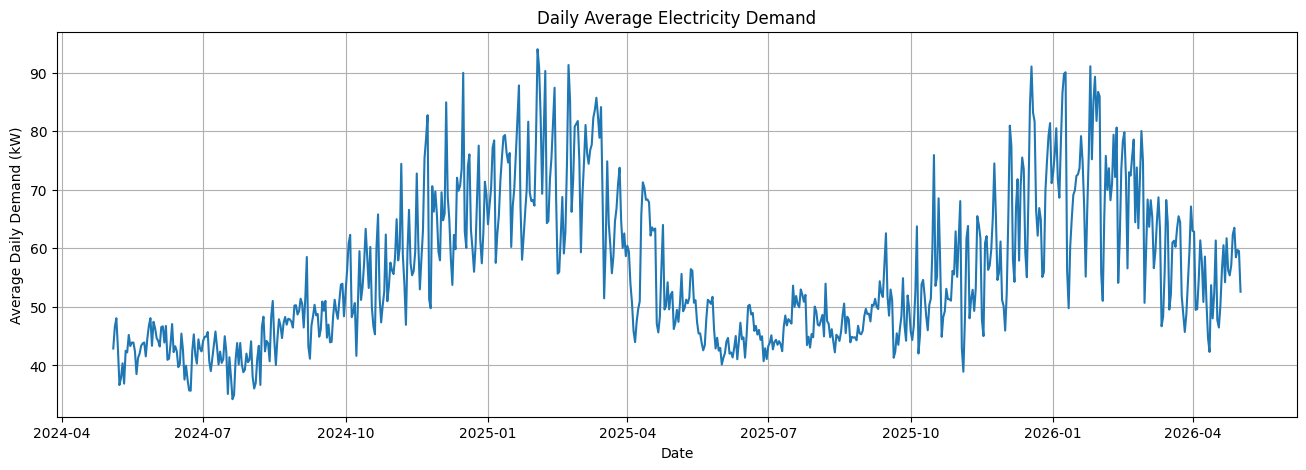

In [9]:
daily = df.set_index("datetime").resample("D").mean(numeric_only=True)

plt.figure(figsize=(16, 5))
plt.plot(daily.index, daily["demand_kW"])

plt.xlabel("Date")
plt.ylabel("Average Daily Demand (kW)")
plt.title("Daily Average Electricity Demand")
plt.grid(True)
plt.show()

/tmp/ipykernel_2168/4107047529.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .resample("M")


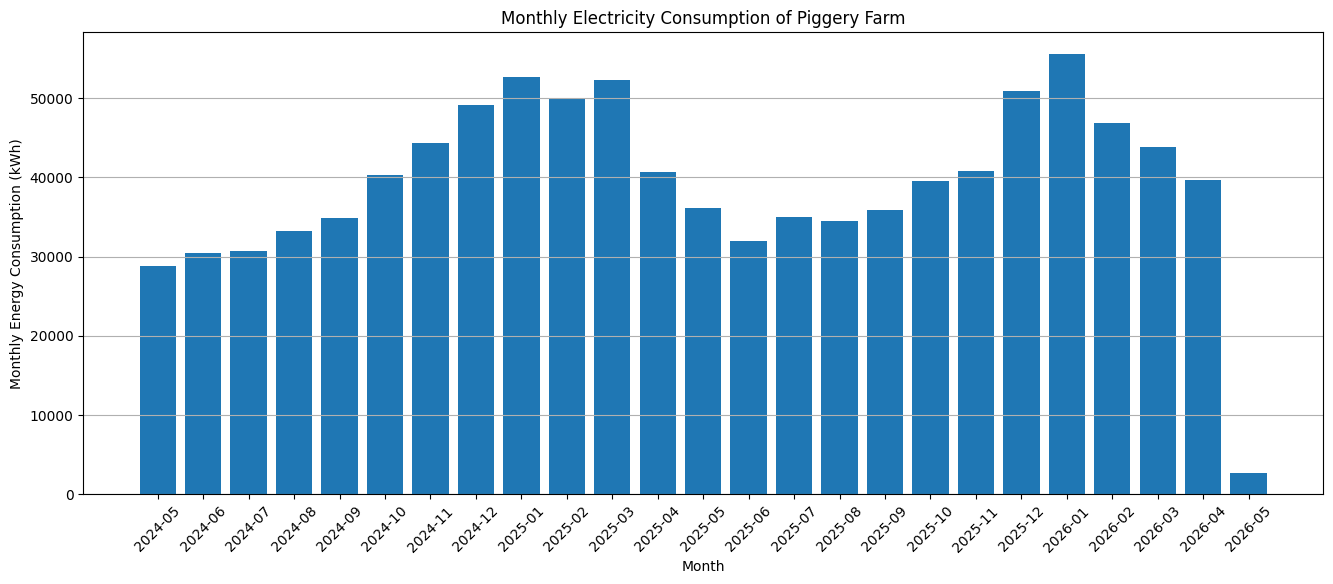

In [10]:
# Monthly total energy consumption
monthly_energy = (
    df.set_index("datetime")["demand_kWh_5min"]
    .resample("M")
    .sum()
)

# Plot
plt.figure(figsize=(16,6))

plt.bar(
    monthly_energy.index.strftime("%Y-%m"),
    monthly_energy.values
)

plt.xlabel("Month")
plt.ylabel("Monthly Energy Consumption (kWh)")
plt.title("Monthly Electricity Consumption of Piggery Farm")

plt.xticks(rotation=45)

plt.grid(axis='y')

plt.show()

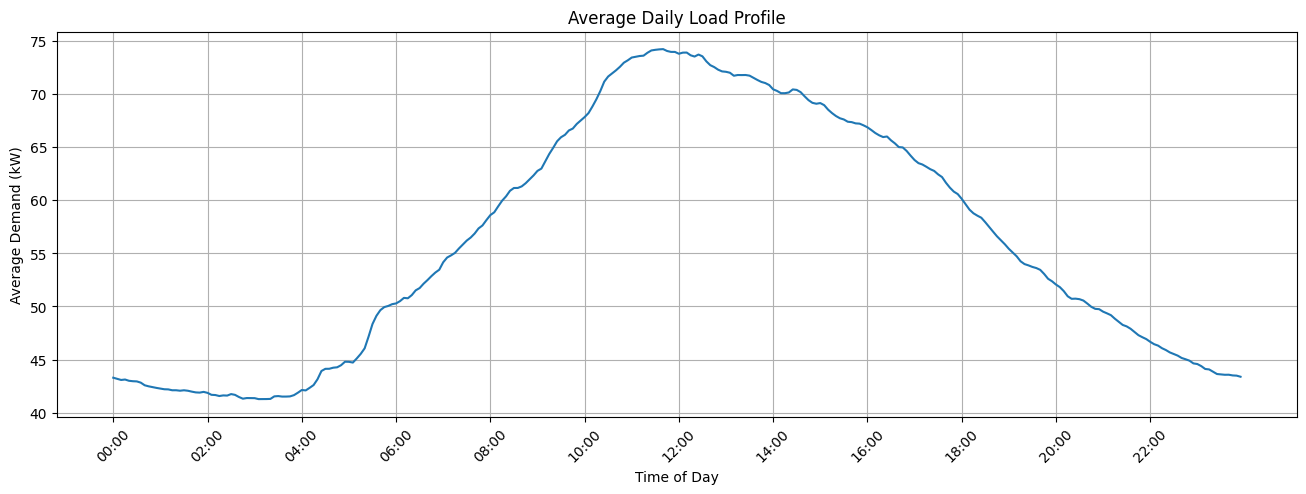

In [11]:
# Create hour column
df["hour"] = df["datetime"].dt.hour
df["minute"] = df["datetime"].dt.minute

# Create time-of-day label
df["time_of_day"] = df["datetime"].dt.strftime("%H:%M")

# Average load for each 5-minute interval across all days
daily_profile = (
    df.groupby("time_of_day")["demand_kW"]
    .mean()
)

# Plot
plt.figure(figsize=(16,5))

plt.plot(daily_profile.index, daily_profile.values)

plt.xlabel("Time of Day")
plt.ylabel("Average Demand (kW)")
plt.title("Average Daily Load Profile")

# Reduce x-axis labels
plt.xticks(
    ticks=range(0, len(daily_profile.index), 24),
    labels=daily_profile.index[::24],
    rotation=45
)

plt.grid(True)

plt.show()

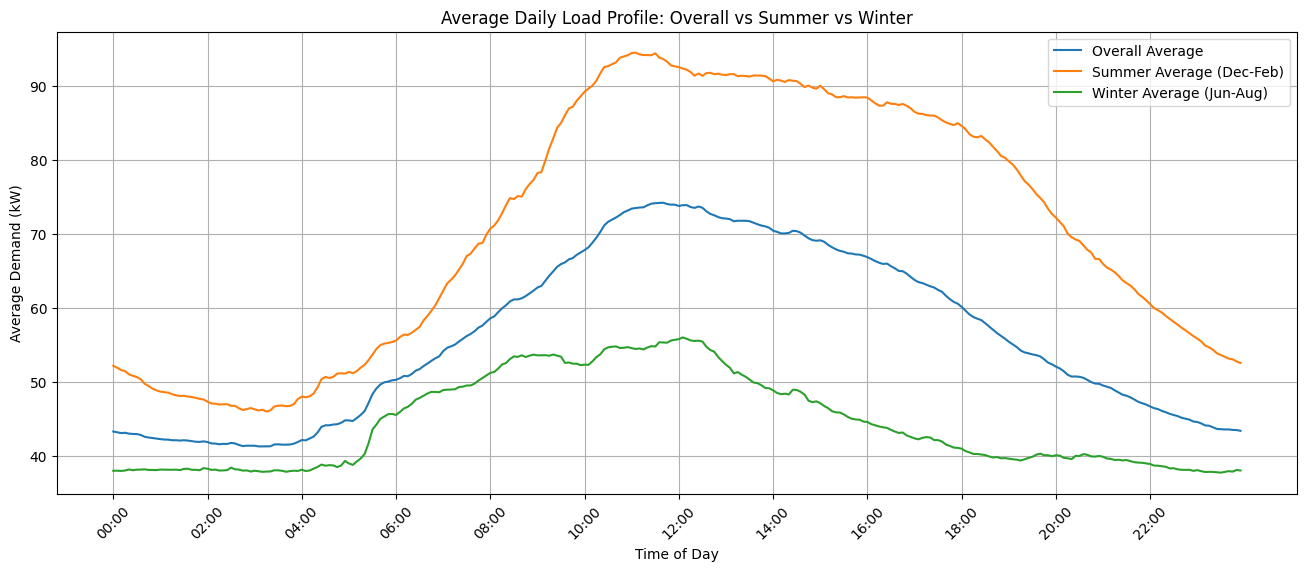

In [12]:
# Add useful time columns
df["month"] = df["datetime"].dt.month
df["time_of_day"] = df["datetime"].dt.strftime("%H:%M")

# Define seasons
summer_df = df[df["month"].isin([12, 1, 2])]
winter_df = df[df["month"].isin([6, 7, 8])]

# Average daily profiles
overall_profile = df.groupby("time_of_day")["demand_kW"].mean()
summer_profile = summer_df.groupby("time_of_day")["demand_kW"].mean()
winter_profile = winter_df.groupby("time_of_day")["demand_kW"].mean()

# Plot
plt.figure(figsize=(16, 6))

plt.plot(overall_profile.index, overall_profile.values, label="Overall Average")
plt.plot(summer_profile.index, summer_profile.values, label="Summer Average (Dec-Feb)")
plt.plot(winter_profile.index, winter_profile.values, label="Winter Average (Jun-Aug)")

plt.xlabel("Time of Day")
plt.ylabel("Average Demand (kW)")
plt.title("Average Daily Load Profile: Overall vs Summer vs Winter")

# Show x-axis label every 2 hours
plt.xticks(
    ticks=range(0, len(overall_profile.index), 24),
    labels=overall_profile.index[::24],
    rotation=45
)

plt.grid(True)
plt.legend()
plt.show()

Peak Day: 2025-02-02 00:00:00


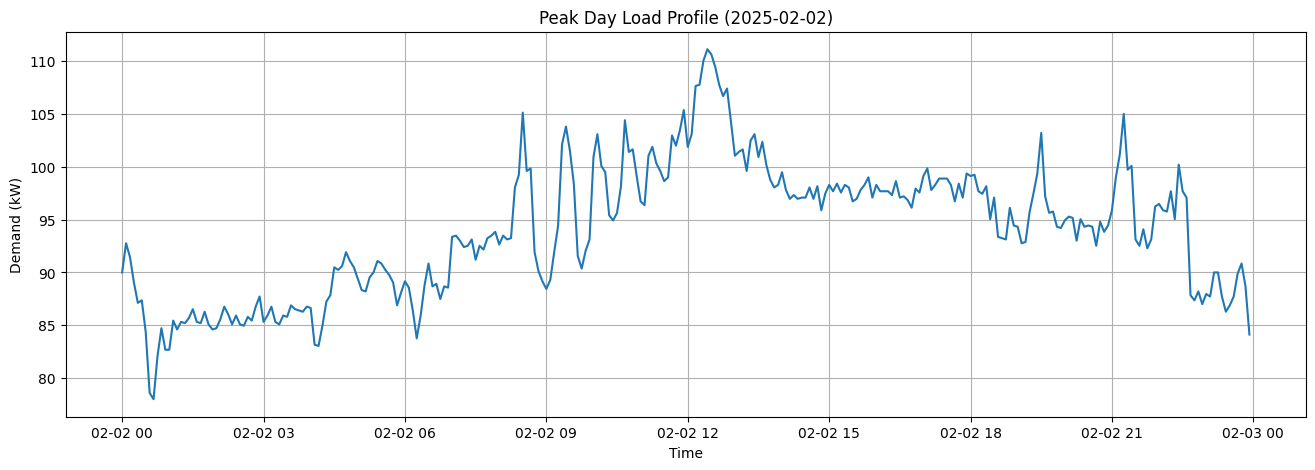

In [13]:
# Calculate daily total energy
daily_energy = (
    df.set_index("datetime")["demand_kWh_5min"]
    .resample("D")
    .sum()
)

# Find highest energy day
peak_day = daily_energy.idxmax()

print("Peak Day:", peak_day)

# Extract that day's data
peak_day_data = df[
    df["datetime"].dt.date == peak_day.date()
]

# Plot
plt.figure(figsize=(16,5))

plt.plot(
    peak_day_data["datetime"],
    peak_day_data["demand_kW"]
)

plt.xlabel("Time")
plt.ylabel("Demand (kW)")
plt.title(f"Peak Day Load Profile ({peak_day.date()})")

plt.grid(True)

plt.show()

In [16]:
# Clean unrealistic low-load records
# 1.5 kWh per 5 min = 18 kW
df_clean = df[
    (df["demand_kWh_5min"] >= 1.5) &
    (df["demand_kWh_5min"] <= 100)
].copy()

print("Original data points:", len(df))
print("Cleaned data points:", len(df_clean))
print(df_clean["demand_kW"].describe())

Original data points: 209506
Cleaned data points: 209484
count    209484.000000
mean         56.174592
std          19.533987
min          18.720000
25%          41.400000
50%          49.440000
75%          66.600000
max         134.520000
Name: demand_kW, dtype: float64


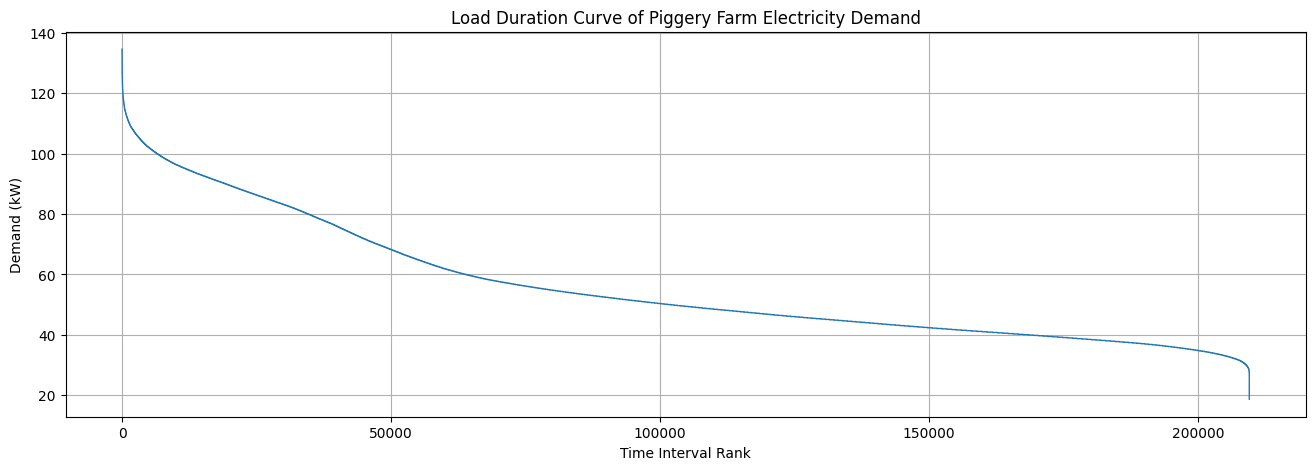

In [17]:
# Load Duration Curve using cleaned data

sorted_load = (
    df_clean["demand_kW"]
    .sort_values(ascending=False)
    .reset_index(drop=True)
)

plt.figure(figsize=(16, 5))

plt.plot(sorted_load, linewidth=1)

plt.xlabel("Time Interval Rank")
plt.ylabel("Demand (kW)")
plt.title("Load Duration Curve of Piggery Farm Electricity Demand")

plt.grid(True)
plt.show()

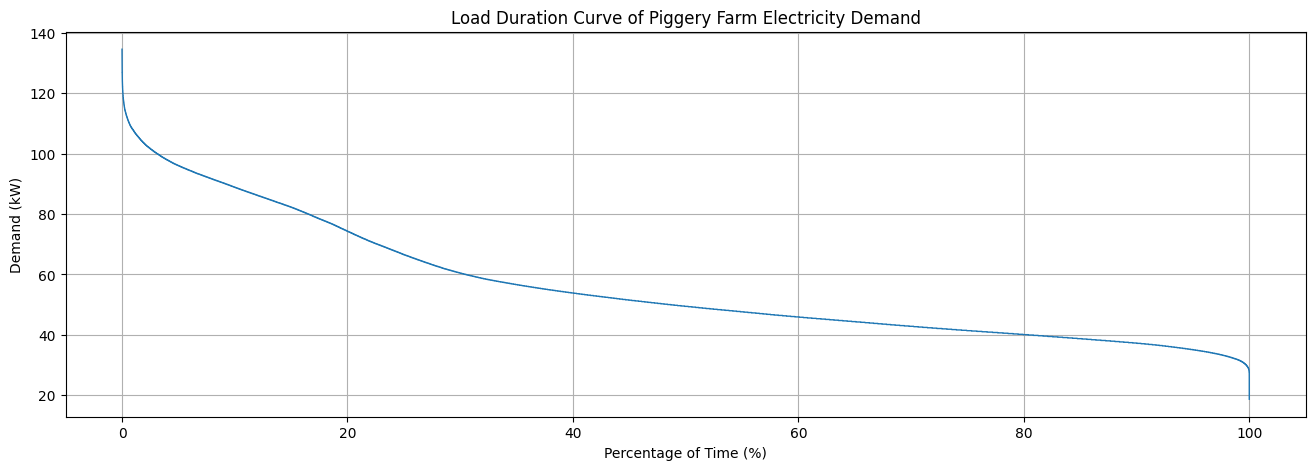

In [18]:
# Load Duration Curve with percentage x-axis

sorted_load = (
    df_clean["demand_kW"]
    .sort_values(ascending=False)
    .reset_index(drop=True)
)

percentage_time = sorted_load.index / (len(sorted_load) - 1) * 100

plt.figure(figsize=(16, 5))

plt.plot(percentage_time, sorted_load, linewidth=1)

plt.xlabel("Percentage of Time (%)")
plt.ylabel("Demand (kW)")
plt.title("Load Duration Curve of Piggery Farm Electricity Demand")

plt.grid(True)
plt.show()